# Entire-home Airbnb listings in London

Both maps use the September 2026 snapshot (`20260917`) from
[Conor’s panel cleaning workflow](https://github.com/andrepianucl17/Foundations_Assessment_Podfather/blob/805d745a004a23903cd615e36fb2f05d4239fb6d/data_prep/cleaning.ipynb).
The local extract contains the columns needed for the maps. We use all listings
flagged as entire homes or apartments, without a recent-review filter. The
borough rates compare these listings with all dwellings on the Council Tax valuation list as of 9 September 2026. The denominator comes from [MHCLG Council Taxbase 2026](https://www.gov.uk/government/statistics/council-taxbase-2026-in-england), local authority workbook, Council Taxbase Data, Table 1.01 (Total). This measure counts dwellings on the valuation list, including Council Tax exempt dwellings.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [2]:
data_dir = Path("data")
listings_file = data_dir / "clean" / "20260917-London-listings-conor-panel.csv.gz"
boros_file = data_dir / "raw" / "Boroughs.gpkg"
stock_file = data_dir / "processed" / "council_tax_dwellings_london_2026.csv"

missing_files = [path for path in (listings_file, boros_file, stock_file) if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Run from the groupwork folder. Missing: {missing_files}")

listings = pd.read_csv(listings_file, dtype={"id": "string", "entire_home": "boolean"})
entire = listings.loc[
    listings["entire_home"].fillna(False), ["id", "borough", "longitude", "latitude"]
].copy()
print(f"Cleaned listings: {len(listings):,}")
print(f"Entire-home listings: {len(entire):,}")

Cleaned listings: 91,954
Entire-home listings: 61,074


In [3]:
boros = gpd.read_file(boros_file)

pts = gpd.GeoDataFrame(
    entire,
    geometry=gpd.points_from_xy(entire["longitude"], entire["latitude"]),
    crs="EPSG:4326",
).to_crs(boros.crs)

## Map 1: every entire-home listing as a point

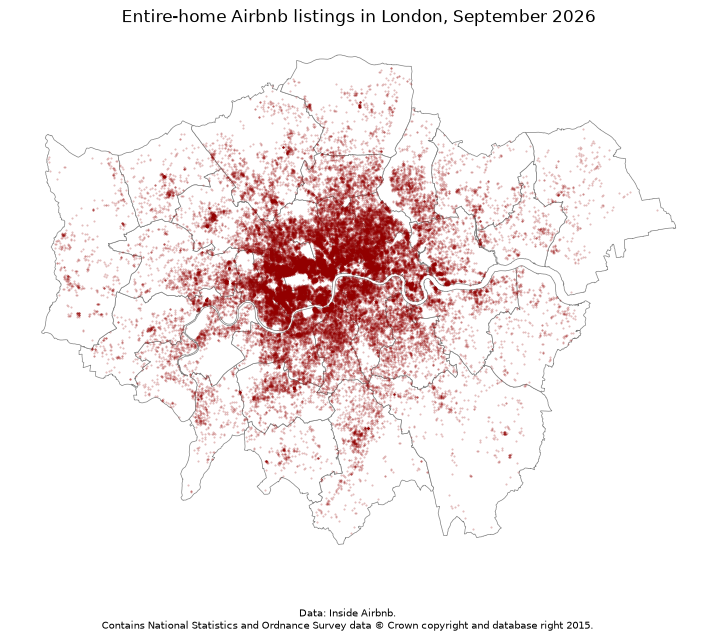

In [4]:
fig, ax = plt.subplots(figsize=(9, 7))

boros.plot(ax=ax, facecolor="white", edgecolor="grey", linewidth=0.5)
pts.plot(ax=ax, color="#920000", markersize=0.2, alpha=0.3)

ax.set_title("Entire-home Airbnb listings in London, September 2026")
ax.set_axis_off()
fig.text(0.5, 0.025, "Data: Inside Airbnb.\nContains National Statistics and Ordnance Survey data © Crown copyright and database right 2015.", ha="center", fontsize=7)
plt.show()

## Borough ranking before Map 2

The rate is the number of entire-home listings per 100 dwellings on the
Council Tax valuation list. The table and Map 2 use the same borough totals.
Ranking uses the unrounded rates.

In [5]:
counts = entire.groupby("borough", observed=True)["id"].nunique().rename("entire_listings")
unknown_boroughs = counts.index.difference(boros["NAME"])
if len(unknown_boroughs) or entire["borough"].isna().any():
    raise ValueError(f"Check missing or unmatched listing boroughs: {list(unknown_boroughs)}")

stock = pd.read_csv(stock_file, usecols=["borough_code", "council_tax_dwellings_2026"])
stock = stock.rename(columns={"borough_code": "GSS_CODE"})
boro_counts = boros.merge(stock, on="GSS_CODE", how="left", validate="one_to_one")
if boro_counts["council_tax_dwellings_2026"].isna().any() or boro_counts["council_tax_dwellings_2026"].le(0).any():
    raise ValueError("Check missing or non-positive valuation-list dwelling counts in the borough join.")

boro_counts["entire_listings"] = boro_counts["NAME"].map(counts).fillna(0).astype(int)
boro_counts["entire_pct"] = 100 * boro_counts["entire_listings"] / boro_counts["council_tax_dwellings_2026"]

borough_ranking = (
    boro_counts[["NAME", "entire_listings", "council_tax_dwellings_2026", "entire_pct"]]
    .sort_values(["entire_pct", "NAME"], ascending=[False, True])
    .reset_index(drop=True)
    .rename(columns={
        "NAME": "Borough",
        "entire_listings": "Entire-home listings",
        "council_tax_dwellings_2026": "Dwellings on Council Tax list (9 Sep 2026)",
        "entire_pct": "Listings per 100 dwellings (%)",
    })
)
borough_ranking.index = borough_ranking.index + 1
borough_ranking.index.name = "Rank"
display(borough_ranking.round({"Listings per 100 dwellings (%)": 2}))

,Borough,Entire-home listings,Dwellings on Council Tax list (9 Sep 2026),Listings per 100 dwellings (%)
Rank,,,,
1,City of London,535,8060,6.64
2,Westminster,8783,132412,6.63
3,Kensington and Chelsea,5428,89790,6.05
4,Camden,4334,114368,3.79
5,Hackney,3793,121311,3.13
6,Hammersmith and Fulham,2915,96847,3.01
7,Islington,3291,112651,2.92
8,Tower Hamlets,4011,153355,2.62
9,Southwark,3180,152441,2.09


## Map 2: entire-home listings per 100 dwellings

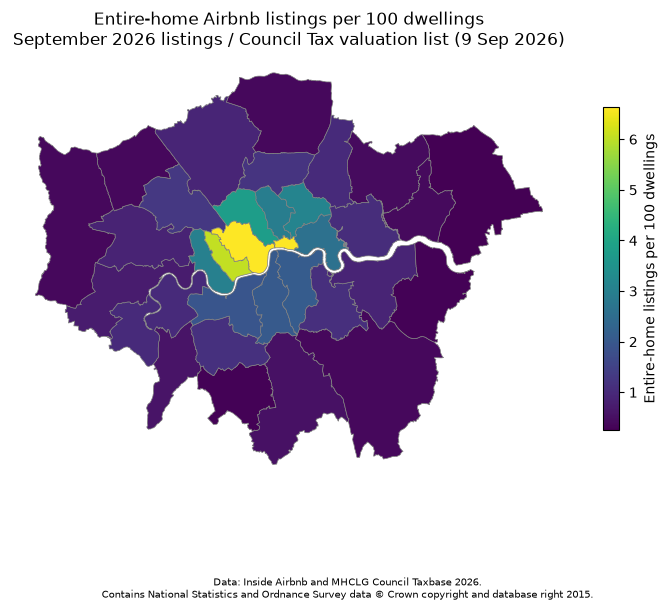

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
boro_counts.plot(
    ax=ax, column="entire_pct", cmap="viridis", edgecolor="grey",
    linewidth=0.5, legend=True,
    legend_kwds={"label": "Entire-home listings per 100 dwellings", "shrink": 0.6},
)

ax.set_title("Entire-home Airbnb listings per 100 dwellings\nSeptember 2026 listings / Council Tax valuation list (9 Sep 2026)")
ax.set_axis_off()
fig.text(0.5, 0.025, "Data: Inside Airbnb and MHCLG Council Taxbase 2026.\nContains National Statistics and Ordnance Survey data © Crown copyright and database right 2015.", ha="center", fontsize=7)
plt.show()